RANDOM FOREST

Problem Statement : Here we are going to predict heart disease based on patient medical records using Random Forest Algorithm.

Step: 1- Importing necessary Libraries

In [ ]:
# Data Handling
import pandas as pd
import numpy as np
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

Step: 2- Loading the Dataset

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Random Forest /heart.csv")   # Loading dataset from drive
df.head()                                                             # Printing top 5 records

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Step: 3- Summarizing the Dataset

In [ ]:
df.shape

(303, 14)

There are 303 rows and 14 columns

In [ ]:
df.info()   # Printing information about the dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


- All 14 columns are including target are numberic.
- No null values present in the dataset.
- Total size of dataset is 33.3kB.

In [ ]:
df.describe() # Printing statistical information about the dataset

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


- All numberic columns with count, mean, std deviation, min, max values, with 25%,50%,75% values.

In [ ]:
df.head() # Top 5 records

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Step: 4 - DATA ANALYSIS

We will try to find any insights in the dataset by analysing column and its impact with target column.

- ***Analysis of Age Column***

First we need to split the dataset into with and without heart diseases.

In [ ]:
df_1 = df[df['target']==1]   # Dataset with heart disease

In [ ]:
df_2 = df[df['target']==0]   # Dataset without heart disease

In [ ]:
df_2

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
165,67,1,0,160,286,0,0,108,1,1.5,1,3,2,0
166,67,1,0,120,229,0,0,129,1,2.6,1,2,3,0
167,62,0,0,140,268,0,0,160,0,3.6,0,2,2,0
168,63,1,0,130,254,0,0,147,0,1.4,1,1,3,0
169,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


There are 138 records which not having heart diseases.

In [ ]:
df['target'].unique()   # Checking howmany unique values in the target column.

array([1, 0])

In [ ]:
df_1['age'].value_counts()   # Counts on each value by age with heart disease present

,count
age,
54,10
41,9
52,9
51,9
44,8
57,7
58,7
42,7
53,6


Convert this into a bar plot for better understanding.

<Axes: xlabel='age'>

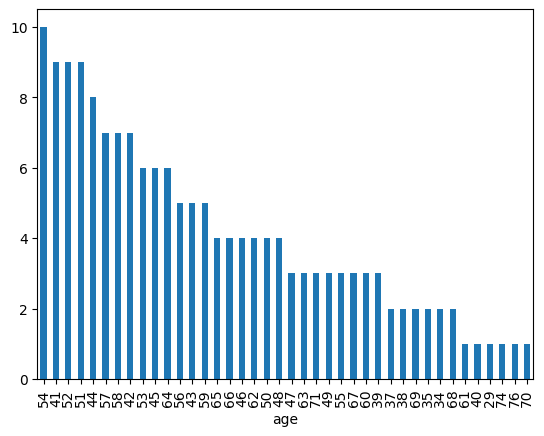

In [ ]:
df_1['age'].value_counts().plot(kind = 'bar')

Age wise count with heart diseases.

<Axes: xlabel='age'>

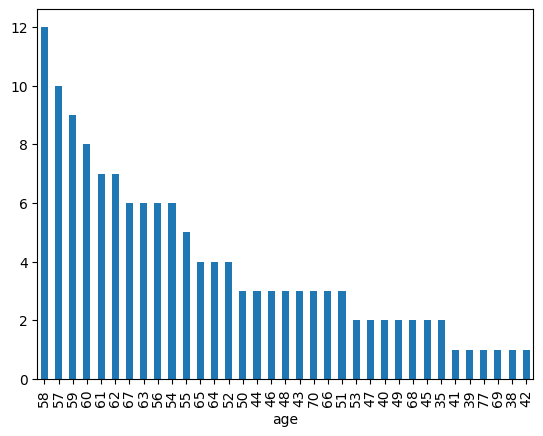

In [ ]:
df_2['age'].value_counts().plot(kind = 'bar')

Age wise count without heart diseases.

- Bar plot shows only the count. We can visualise the data using histogram to see the distribution of data.

<Axes: ylabel='Frequency'>

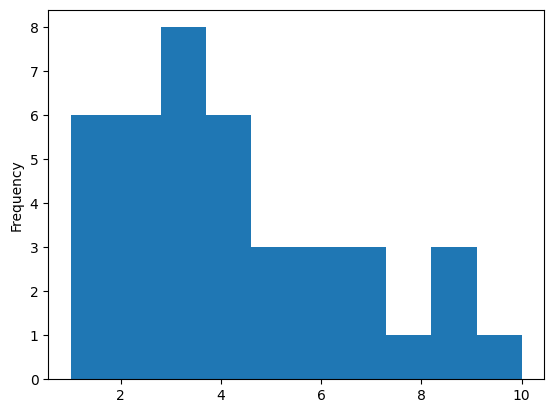

In [ ]:
df_1['age'].value_counts().plot(kind = 'hist')

(array([ 1.,  8., 25., 21., 29., 31., 16., 21., 11.,  2.]),
 array([29. , 33.7, 38.4, 43.1, 47.8, 52.5, 57.2, 61.9, 66.6, 71.3, 76. ]),
 <BarContainer object of 10 artists>)

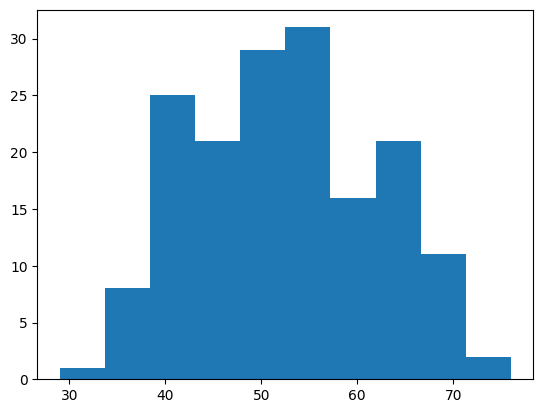

In [ ]:
plt.hist(df_1['age'])  # Visualise using matplotlib for better understanding

- Age ranges approx from 30 to 76 years, indicating broad distribution with heart distribution present.
- Most observations are concentrated between 40 and 60 years, with fewer people at the younger and older at the ends.The maximum around the age of 55.

(array([ 4.,  7., 10., 11., 17., 45., 24., 15.,  4.,  1.]),
 array([35. , 39.2, 43.4, 47.6, 51.8, 56. , 60.2, 64.4, 68.6, 72.8, 77. ]),
 <BarContainer object of 10 artists>)

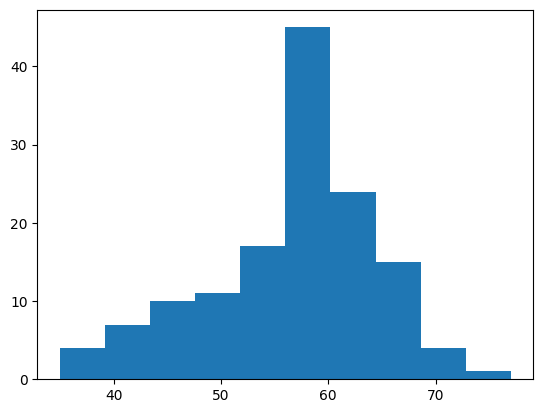

In [ ]:
plt.hist(df_2['age'])

- Age ranges around 30 to 77 years, indicating broad distribution without heart distribution present.
- Most observations are concentrated between 55 and 65 years.The maximum around the age of 58.

(array([ 1., 11., 33., 38., 37., 60., 63., 43., 14.,  3.]),
 array([29. , 33.8, 38.6, 43.4, 48.2, 53. , 57.8, 62.6, 67.4, 72.2, 77. ]),
 <BarContainer object of 10 artists>)

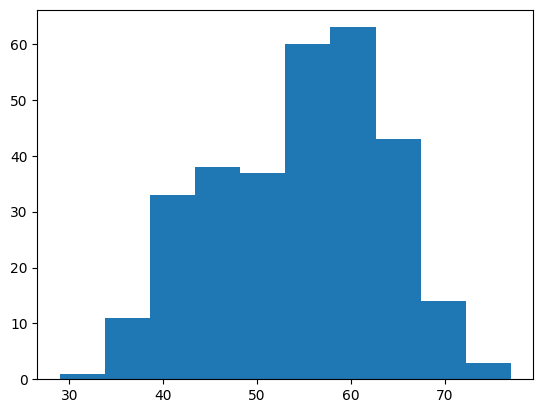

In [ ]:
plt.hist(df['age'])   # Total distribution of age

- Most individuals are between 40 and 65 years old, with the highest concentration around 55–65 years.

- The distribution is roughly bell-shaped, with fewer individuals at the younger and older age ranges.

In [ ]:
# Create a dataframe with age between 55 to 65.

df_3 = df[(df['age']>=55) & (df['age']<=65)]
df_3.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1


In [ ]:
df_3.isnull().sum()   # Checking any null values in the dataset

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


As we already know, there are no null values in the dataset.

In [ ]:
df_3['age'].unique()  # printing the unique values in these age ranges

array([63, 56, 57, 64, 58, 59, 61, 65, 62, 55, 60])

(array([ 8., 11., 17., 19., 14., 11.,  8., 11.,  9., 18.]),
 array([55., 56., 57., 58., 59., 60., 61., 62., 63., 64., 65.]),
 <BarContainer object of 10 artists>)

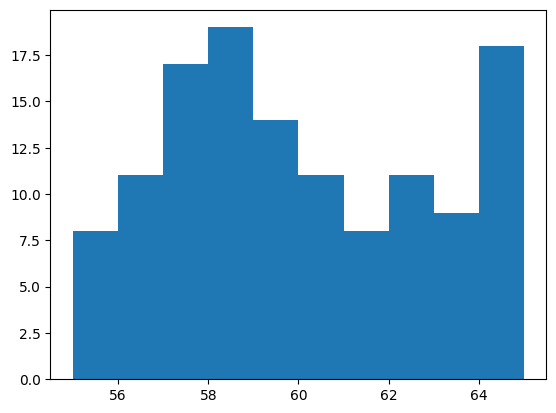

In [ ]:
plt.hist(df_3['age'])

- The histogram shows the age distribution of patients between 55 and 65 years.

- The highest frequencies occur around 58–59 and 64–65 years, while ages around 61–63 are less frequent.

In [ ]:
len(df_3)

126

Total record is 126 in the age between 55 to 65.

In [ ]:
df_3[df_3['target']==1]  # Printing the records with heart disease present.

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1
13,64,1,3,110,211,0,0,144,1,1.8,1,0,2,1
14,58,0,3,150,283,1,0,162,0,1.0,2,0,2,1
16,58,0,2,120,340,0,1,172,0,0.0,2,0,2,1
20,59,1,0,135,234,0,1,161,0,0.5,1,0,3,1


In [ ]:
df_3[df_3['target']==0]  # Printing the records without heart disease present.

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
167,62,0,0,140,268,0,0,160,0,3.6,0,2,2,0
168,63,1,0,130,254,0,0,147,0,1.4,1,1,3,0
170,56,1,2,130,256,1,0,142,1,0.6,1,1,1,0
172,58,1,1,120,284,0,0,160,0,1.8,1,0,2,0
173,58,1,2,132,224,0,0,173,0,3.2,2,2,3,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
296,63,0,0,124,197,0,1,136,1,0.0,1,0,2,0
297,59,1,0,164,176,1,0,90,0,1.0,1,2,1,0
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [ ]:
df_4 = df_3[df_3['target']==1] # Dataframe with heart disease from the age b/w 55 to 65.

In [ ]:
df_5 = df_3[df_3['target']==0]  # Dataframe without heart disease from the age b/w 55 to 65.

(array([ 3.,  5.,  7.,  7.,  5.,  3.,  1.,  4.,  3., 10.]),
 array([55., 56., 57., 58., 59., 60., 61., 62., 63., 64., 65.]),
 <BarContainer object of 10 artists>)

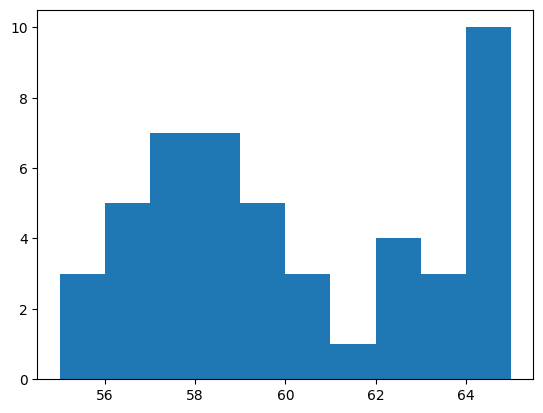

In [ ]:
plt.hist(df_4['age'])

- The histogram shows heart disease cases among people aged 55–65 years, with cases spread across the entire age range.

- The highest frequency is observed around 64–65 years, while the lowest occurs around 61 years.

(array([ 5.,  6., 10., 12.,  9.,  8.,  7.,  7.,  6.,  8.]),
 array([55., 56., 57., 58., 59., 60., 61., 62., 63., 64., 65.]),
 <BarContainer object of 10 artists>)

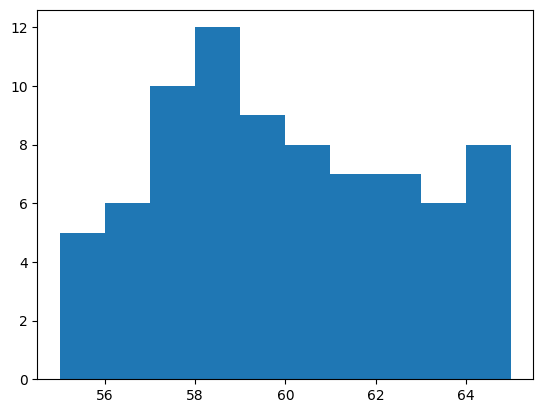

In [ ]:
plt.hist(df_5['age'])

- The histogram shows that the age distribution without heart disease is fairly spread across ages 55–65, with the highest frequency around 58 years.

- The distribution is moderately varied, with fewer individuals at ages 55–56 and 63–64, while ages 58–60 have relatively higher frequencies.

- ***Data Analysis by gender column***

In [ ]:
df['sex'].value_counts()

,count
sex,
1,207
0,96


Here 207 records are male and 96 records are female.

In [ ]:
df_m = df[df['sex']==1]  # Dataframe with Male

In [ ]:
df_f = df[df['sex']==0]  # Dataframe with Female

In [ ]:
df_m['target'].value_counts()

,count
target,
0,114
1,93


Out of 207 records, 93 males are having heart disease and 114 are not having heart diseases.

In [ ]:
df_f['target'].value_counts()

,count
target,
1,72
0,24


Out of 96 records, 72 Females are having heart disease and 24 are not having heart diseases.

While comparing the both male and female records having heart disease. More number Females having heart diseases in ratio with total female records than males.


In [ ]:
df['target'].value_counts()

,count
target,
1,165
0,138


In [ ]:
df.head(15)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1


Next, we will try to find the correlation between the features with target using Heatmap.

<Axes: >

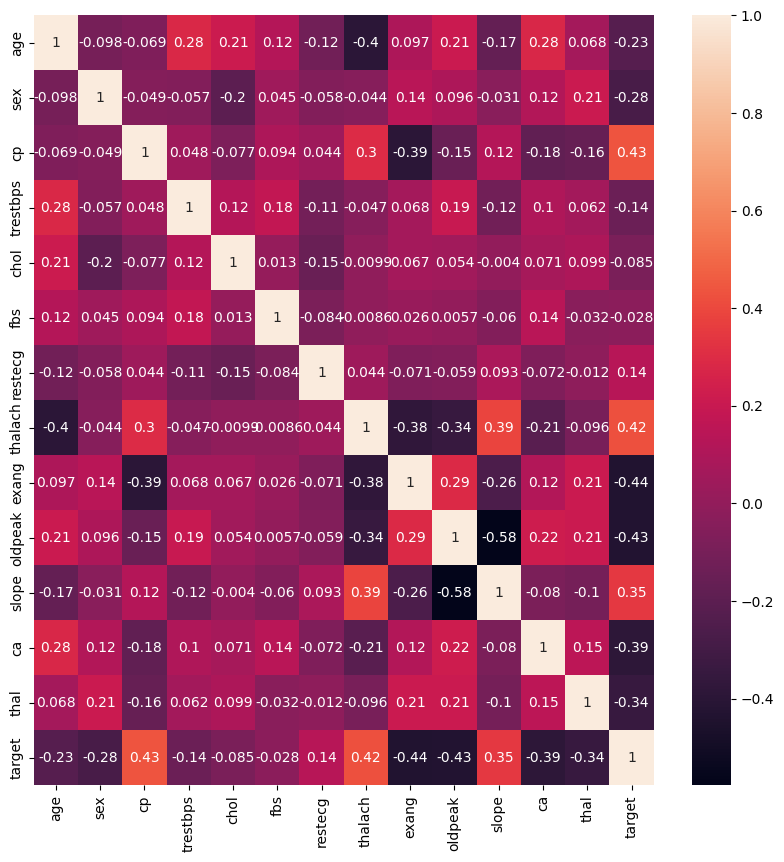

In [ ]:
plt.figure(figsize = (10,10))
sns.heatmap(df.corr(), annot = True)


- `The heatmap shows mostly weak to moderate correlations. The strongest relationship with the target is cp (0.43) and thalach (0.42), both showing moderate positive correlation.`

- `No feature has a very strong linear correlation with the target.`

**Why do we use Random Forest for this heart disease prediction?**

We use Random forest algorithm for this usecase:

- It can capture non linear relationship between the features. From the heatmap, we found that most features are any direct relationship with target.


- It works well with more number of features.

- It gives feature importance. In heart disease prediction, not only predict disease/ Non Disease. Also find which feature contributes most to the models prediction.  

In [ ]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Step: 5 - Segregating the dataset into input and output

In [ ]:
X = df.iloc[:,:-1].values

Defining X values with only input features

In [ ]:
X

array([[63.,  1.,  3., ...,  0.,  0.,  1.],
       [37.,  1.,  2., ...,  0.,  0.,  2.],
       [41.,  0.,  1., ...,  2.,  0.,  2.],
       ...,
       [68.,  1.,  0., ...,  1.,  2.,  3.],
       [57.,  1.,  0., ...,  1.,  1.,  3.],
       [57.,  0.,  1., ...,  1.,  1.,  2.]])

In [ ]:
Y = df['target'].values

Defining the output variable(Target)

In [ ]:
Y

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

Step: 6 - Splitting the dataset into training and testing

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state=42)

Splitting dataset for training and testing with 80%-20%.

In [ ]:
X.shape, Y.shape

((303, 13), (303,))

In [ ]:
X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((242, 13), (61, 13), (242,), (61,))

Step: 7 - Loading the model

In [ ]:
model = RandomForestClassifier(n_estimators=100)

Loading random forest classifier model with 100 decision trees.

In [ ]:
model

RandomForestClassifier()

Step: 8 - Training the model

In [ ]:
model.fit(X_train,Y_train)

RandomForestClassifier()

Step: 9 - Predicting the result using the trained model

In [ ]:
y_pred  = model.predict(X_test)

In [ ]:
y_pred

array([0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0])

Step: 10 - Calculating the accuracy using the trained model

In [ ]:
accuracy_score(Y_test, y_pred)

0.8524590163934426

- Got the accuracy score of 85% which is decent for this type of dataset. However we need to try out different parameters to find the accuracy score.
- The remaining 14.75% of predictions were incorrect, so there is still scope for improvement.

In [ ]:
print(classification_report(Y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.83      0.84        29
           1       0.85      0.88      0.86        32

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61



- Class 0 (No Heart Disease): The model achieved 86% precision, 83% recall and 84% F1-score, indicating good performance in identifying patients without heart disease.

- Class 1 (Heart Disease): The model achieved 85% precision, 88% recall and 86% F1-score, showing that it correctly identifies most patients with heart disease.

- Recall of 88% for Class 1: The model successfully identified approximately 88% of actual heart disease cases. This is particularly important in medical prediction, as missing a potential case can be serious.

- Overall accuracy of 85%: The model correctly classified approximately 85% of the 61 test samples, demonstrating promising classification performance.

Step: 11 - Predicting the output of single sample using the training data

In [ ]:
X_test[0]

array([ 57. ,   1. ,   0. , 150. , 276. ,   0. ,   0. , 112. ,   1. ,
         0.6,   1. ,   1. ,   1. ])

In [ ]:
Y_test[0]

np.int64(0)

In [ ]:
model.predict(X_test[0].reshape(1,-1))

array([0])

It is predicted correctly for the sample data. Similarly we will try few more samples.

In [ ]:
X_test[2]

array([ 57. ,   1. ,   2. , 150. , 126. ,   1. ,   1. , 173. ,   0. ,
         0.2,   2. ,   1. ,   3. ])

In [ ]:
Y_test[2]

np.int64(1)

In [ ]:
model.predict(X_test[2].reshape(1,-1))

array([1])

In [ ]:
X_test[5]

array([ 57. ,   1. ,   2. , 150. , 168. ,   0. ,   1. , 174. ,   0. ,
         1.6,   2. ,   0. ,   2. ])

In [ ]:
Y_test[5]

np.int64(1)

In [ ]:
model.predict(X_test[5].reshape(1,-1))

array([1])

In [ ]:
X_test[10]

array([ 57. ,   1. ,   0. , 140. , 192. ,   0. ,   1. , 148. ,   0. ,
         0.4,   1. ,   0. ,   1. ])

In [ ]:
Y_test[10]

np.int64(1)

In [ ]:
model.predict(X_test[10].reshape(1,-1))

array([1])

For some sample it predicted correcly and some it is not predicted. Since we got only 85% accuracy.


n_estimators = 1,
accuracy = 75%

n_estimators = 5,
accuracy = 77%

n_estimators = 50,
accuracy = 85%

n_estimators = 100,
accuracy = 82%

n_estimators = 200,
accuracy = 84%

n_estimators = 300,
accuracy = 83%

n_estimators = 500,
accuracy = 87%

- 5 trees (77% accuracy): The model has relatively low accuracy, possibly because too few trees are used to capture the patterns in the dataset.

- 50 trees (85% accuracy): Accuracy improves significantly, suggesting that increasing the number of trees helps the model learn more stable patterns.

- 100–300 trees (82–84% accuracy): Accuracy fluctuates slightly rather than increasing consistently. Adding more trees does not guarantee better accuracy on a particular test set.

- 500 trees (87% accuracy): This gives the highest accuracy among the tested values, indicating the best observed performance in this experiment.


Overall observation: Increasing the number of trees can improve the stability of Random Forest predictions, but accuracy depends on other factors, such as the data split, random state and model parameters.

The highest observed accuracy is 87% with 500 trees. However, more trees also require more computational time, and this result alone does not prove that 500 is the optimal value.

Step: 12 - Visualizing the random forest voting for single test data

In [ ]:
model

RandomForestClassifier()

In [ ]:
model.estimators_

[DecisionTreeClassifier(max_features='sqrt', random_state=1059233615),
 DecisionTreeClassifier(max_features='sqrt', random_state=1598803633),
 DecisionTreeClassifier(max_features='sqrt', random_state=1185143407),
 DecisionTreeClassifier(max_features='sqrt', random_state=1147292774),
 DecisionTreeClassifier(max_features='sqrt', random_state=1151062826),
 DecisionTreeClassifier(max_features='sqrt', random_state=1162145953),
 DecisionTreeClassifier(max_features='sqrt', random_state=388377070),
 DecisionTreeClassifier(max_features='sqrt', random_state=200183860),
 DecisionTreeClassifier(max_features='sqrt', random_state=979547837),
 DecisionTreeClassifier(max_features='sqrt', random_state=977646220),
 DecisionTreeClassifier(max_features='sqrt', random_state=430571474),
 DecisionTreeClassifier(max_features='sqrt', random_state=417814104),
 DecisionTreeClassifier(max_features='sqrt', random_state=1177505586),
 DecisionTreeClassifier(max_features='sqrt', random_state=692284637),
 DecisionTree

This is the output of our Random Forest model with 100 decision trees (n_estimators=100).

- Each DecisionTreeClassifier represents an individual decision tree within the Random Forest.

- max_features='sqrt' means each tree considers a randomly selected subset of features at each split, approximately the square root of the total number of features.

- random_state is a different random seed for each tree, helping introduce diversity among the trees.

- All 100 trees contribute to the final prediction through majority voting in our classification problem.

- Combining multiple diverse trees helps reduce the risk of overfitting compared with relying on a single decision tree.

In [ ]:
len(model.estimators_)

100

In [ ]:
X_test[0]

array([ 57. ,   1. ,   0. , 150. , 276. ,   0. ,   0. , 112. ,   1. ,
         0.6,   1. ,   1. ,   1. ])

In [ ]:
Y_test[0]

np.int64(0)

In [ ]:
model.predict(X_test[0].reshape(1,-1))

array([0])

Checking the actual value and model prediction for the sample data.

In [ ]:
model.estimators_

[DecisionTreeClassifier(max_features='sqrt', random_state=1059233615),
 DecisionTreeClassifier(max_features='sqrt', random_state=1598803633),
 DecisionTreeClassifier(max_features='sqrt', random_state=1185143407),
 DecisionTreeClassifier(max_features='sqrt', random_state=1147292774),
 DecisionTreeClassifier(max_features='sqrt', random_state=1151062826),
 DecisionTreeClassifier(max_features='sqrt', random_state=1162145953),
 DecisionTreeClassifier(max_features='sqrt', random_state=388377070),
 DecisionTreeClassifier(max_features='sqrt', random_state=200183860),
 DecisionTreeClassifier(max_features='sqrt', random_state=979547837),
 DecisionTreeClassifier(max_features='sqrt', random_state=977646220),
 DecisionTreeClassifier(max_features='sqrt', random_state=430571474),
 DecisionTreeClassifier(max_features='sqrt', random_state=417814104),
 DecisionTreeClassifier(max_features='sqrt', random_state=1177505586),
 DecisionTreeClassifier(max_features='sqrt', random_state=692284637),
 DecisionTree

Creating a list for model estimators along with its predictions.

In [ ]:
val_lst = []

for tree in model.estimators_:
  print(tree)
  print(tree.predict(X_test[0].reshape(1,-1)))
  val_lst.append(tree.predict(X_test[0].reshape(1,-1)))

DecisionTreeClassifier(max_features='sqrt', random_state=1059233615)
[0.]
DecisionTreeClassifier(max_features='sqrt', random_state=1598803633)
[0.]
DecisionTreeClassifier(max_features='sqrt', random_state=1185143407)
[0.]
DecisionTreeClassifier(max_features='sqrt', random_state=1147292774)
[0.]
DecisionTreeClassifier(max_features='sqrt', random_state=1151062826)
[1.]
DecisionTreeClassifier(max_features='sqrt', random_state=1162145953)
[0.]
DecisionTreeClassifier(max_features='sqrt', random_state=388377070)
[0.]
DecisionTreeClassifier(max_features='sqrt', random_state=200183860)
[0.]
DecisionTreeClassifier(max_features='sqrt', random_state=979547837)
[0.]
DecisionTreeClassifier(max_features='sqrt', random_state=977646220)
[0.]
DecisionTreeClassifier(max_features='sqrt', random_state=430571474)
[0.]
DecisionTreeClassifier(max_features='sqrt', random_state=417814104)
[0.]
DecisionTreeClassifier(max_features='sqrt', random_state=1177505586)
[0.]
DecisionTreeClassifier(max_features='sqrt', 

In [ ]:
val_lst

[array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([1.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([1.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([1.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([1.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([1.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([1.]),
 array([1.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([1.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([1.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array([0.]),
 array

In [ ]:
len(val_lst)

100

In [ ]:
val_lst.count(1)

12

In [ ]:
val_lst.count(0)

88

Out of 100 records, predicted 88 records without heart disease and 12 records with heart disease.

In [ ]:
model.predict(X_test[0].reshape(1,-1))

array([0])

Model predicted correctly for a sample data.